# Tugas - Medical Cost Prediction

| Nama | NRP |
|------|-----|
| Daffa Aufa Afif | 5054251022 |

## Deskripsi Tugas

Pada tugas ini, kita akan menggunakan Medical Cost Personal Dataset dari Kaggle.

Dataset:
- https://www.kaggle.com/mirichoi0218/insurance

Target yang diprediksi adalah `charges`.

Model yang digunakan:
1. Linear Regression
2. Polynomial Regression
3. Ridge Regression
4. Lasso Regression
5. Decision Tree Regressor
6. Support Vector Regression


# 1. Persiapan Dataset dan Eksplorasi Awal

In [33]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
RANDOM_STATE = 42


In [34]:
# Dataset disimpan bersama notebook; tidak mengunduh atau mengisi cache di luar folder.

import kagglehub
path = kagglehub.dataset_download("mirichoi0218/insurance")
path +="/insurance.csv"
print("Dataset:", path)


Using Colab cache for faster access to the 'insurance' dataset.
Dataset: /kaggle/input/insurance/insurance.csv


In [35]:
df = pd.read_csv(path)

In [36]:
# Tampilkan beberapa baris pertama dataset.
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [37]:
# Tampilkan informasi dataset.
print(df.info())
print(df.describe())
print(df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max

In [38]:
# Periksa missing value.
print(df.isnull().sum())

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [39]:
# Tampilkan statistik deskriptif fitur numerik.
numerik = df.dtypes[df.dtypes != "object"].index
df[numerik].describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [40]:
# Tampilkan jumlah nilai pada setiap fitur kategorikal.
category = df.dtypes[df.dtypes == "object"].index
for i in category:
  print(df[i].value_counts(),end=" \n\n")

sex
male      676
female    662
Name: count, dtype: int64 

smoker
no     1064
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64 



## Lakukan Exploratory Data Analysis (EDA) sederhana yang diperlukan.


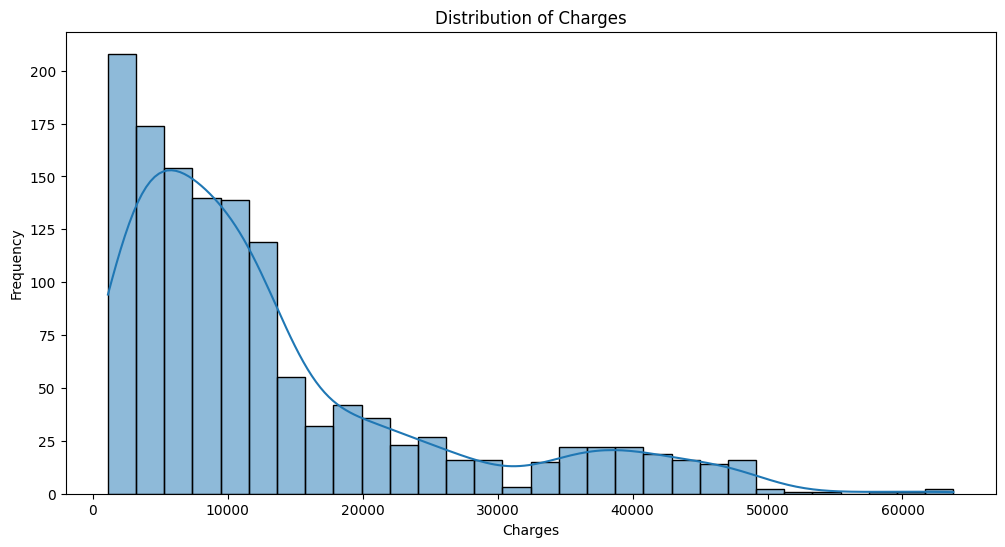

In [41]:
# Show `charges` distribution
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='charges', kde=True)
plt.title('Distribution of Charges')
plt.xlabel('Charges')
plt.ylabel('Frequency')
plt.show()


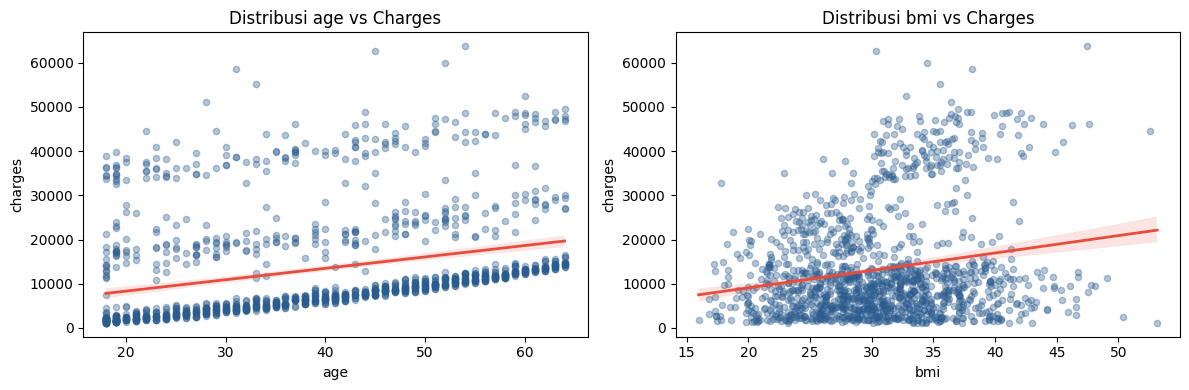

In [42]:
# Histogram continuous feature and `charges`
fitur_input = [col for col in numerik if col != 'charges' and col!='children']
cols = 2
rows = (len(fitur_input) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))
axes = axes.flatten()

for i, col in enumerate(fitur_input):
  sns.regplot(
    data=df,
    x=col,
    y='charges',
    ax=axes[i],
    scatter_kws={
        'alpha': 0.35,
        's': 20,
        'color': '#2b5c8f',
    },  # Pengaturan titik data
    line_kws={
        'color': '#e74c3c',
        'linewidth': 2,
    },  # Pengaturan garis regresi
    ci=95,  # Confidence interval (default 95%)
)
  axes[i].set_title(f'Distribusi {col} vs Charges')

for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


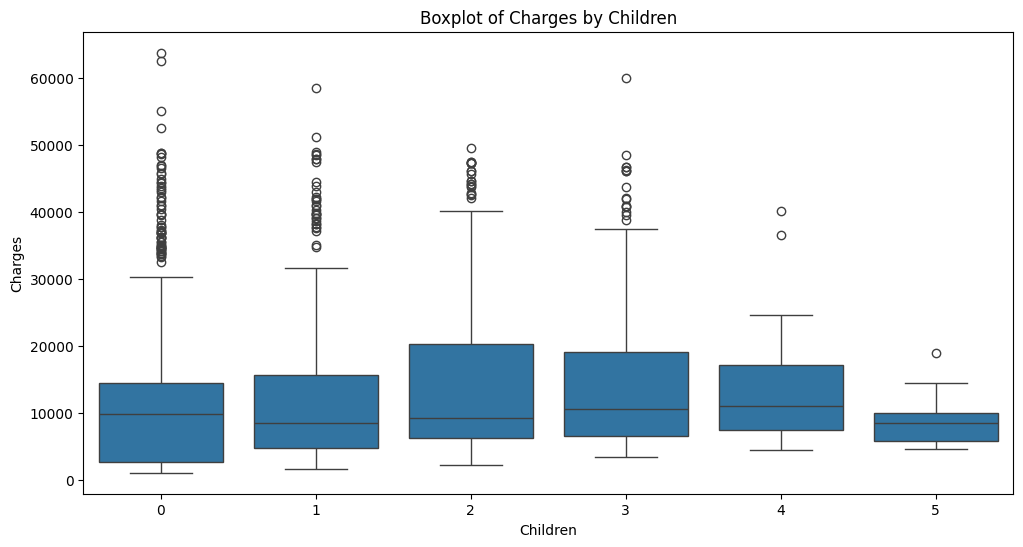

In [43]:
# Boxplot for children feature
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='children', y='charges')
plt.title('Boxplot of Charges by Children')
plt.xlabel('Children')
plt.ylabel('Charges')
plt.show()

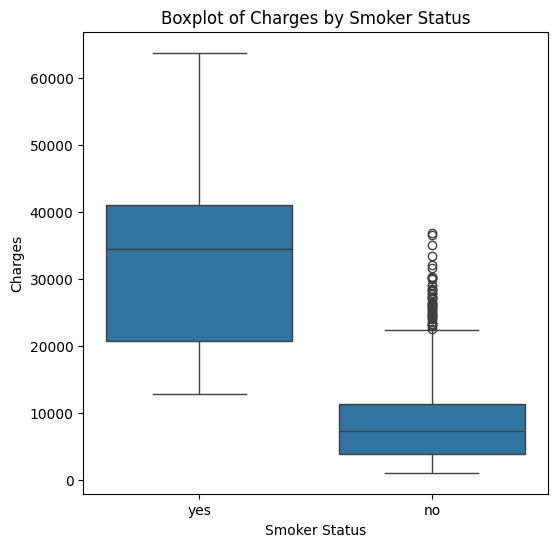

In [44]:
# box plot untuk smoker status
plt.figure(figsize=(6, 6))
sns.boxplot(data=df, x='smoker', y='charges')
plt.title('Boxplot of Charges by Smoker Status')
plt.xlabel('Smoker Status')
plt.ylabel('Charges')
plt.show()

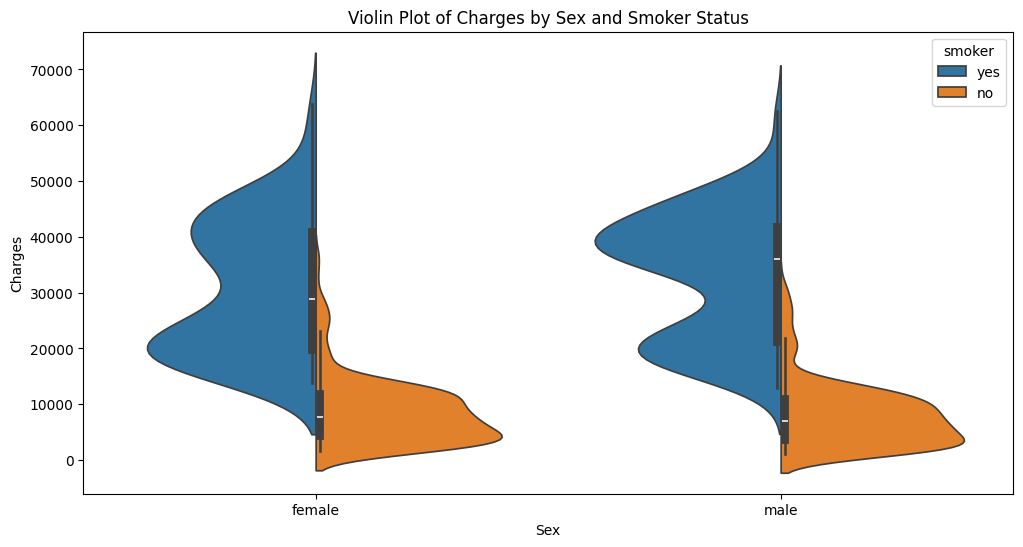

In [45]:
# violin plot for categorical feature
plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='sex', y='charges', hue='smoker', split=True)
plt.title('Violin Plot of Charges by Sex and Smoker Status')
plt.xlabel('Sex')
plt.ylabel('Charges')
plt.show()

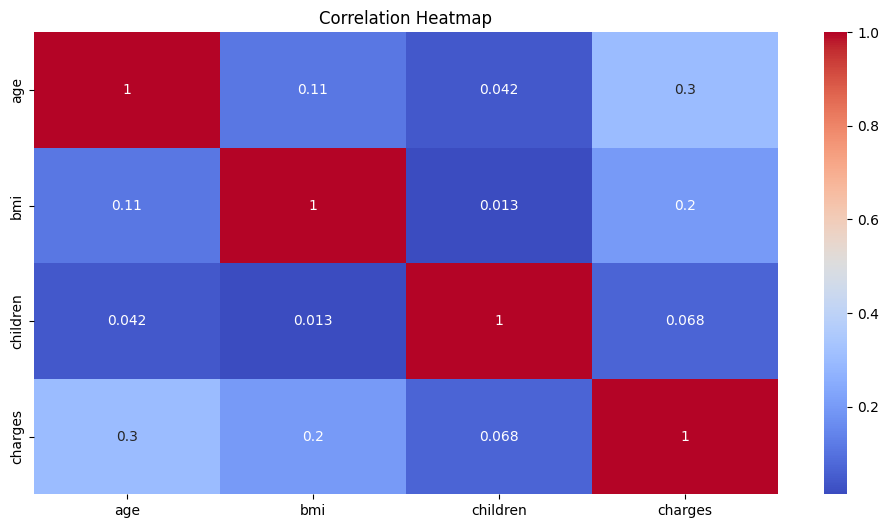

In [46]:
# Corralation heat map
plt.figure(figsize=(12, 6))
sns.heatmap(df[numerik].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

# 2. Preprocessing

Data berisi 1.338 observasi dan tujuh kolom. Target `charges` kontinu dan miring ke kanan. EDA menunjukkan perbedaan biaya besar menurut `smoker`; hubungan BMI–biaya juga berbeda antara perokok dan bukan perokok. Satu baris duplikat dibuang sebelum split agar salinannya tidak tersebar ke train dan test. Tidak ada nilai kosong.

Fitur numerik diimputasi median lalu distandardisasi untuk model linear, polynomial, Ridge, Lasso, dan SVR. Fitur kategorikal diimputasi modus lalu di-*one-hot encode*. Decision Tree memakai fitur numerik tanpa scaling karena ambang pemisahannya tidak bergantung pada satuan. Semua transformasi berada di dalam `Pipeline`, sehingga fit hanya dilakukan pada fold training.


In [47]:
df_model = df.drop_duplicates().reset_index(drop=True)
X = df_model.drop(columns="charges")
y = df_model["charges"]
print(f"Awal: {len(df)}; duplikat: {len(df)-len(df_model)}; dipakai: {len(df_model)}")
print("Skewness charges:", round(y.skew(), 3))
print("Median charges menurut smoker:")
print(df_model.groupby("smoker")["charges"].median().round(2))


Awal: 1338; duplikat: 1; dipakai: 1337
Skewness charges: 1.515
Median charges menurut smoker:
smoker
no      7345.73
yes    34456.35
Name: charges, dtype: float64


In [48]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
print("Numerik:", numeric_features)
print("Kategorikal:", categorical_features)


Numerik: ['age', 'bmi', 'children']
Kategorikal: ['sex', 'smoker', 'region']


In [49]:
# Test ditahan sampai semua konfigurasi dipilih dari CV pada train.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=X["smoker"]
)
print("Train/test:", X_train.shape, X_test.shape)
print("Proporsi smoker=yes train/test:",
      round(X_train["smoker"].eq("yes").mean(), 3),
      round(X_test["smoker"].eq("yes").mean(), 3))


Train/test: (1069, 6) (268, 6)
Proporsi smoker=yes train/test: 0.205 0.205


In [50]:
numeric_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
numeric_unscaled = Pipeline([("imputer", SimpleImputer(strategy="median"))])
categorical = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess_scaled = ColumnTransformer([
    ("numeric", numeric_scaled, numeric_features),
    ("categorical", categorical, categorical_features),
], sparse_threshold=0)
preprocess_tree = ColumnTransformer([
    ("numeric", numeric_unscaled, numeric_features),
    ("categorical", categorical, categorical_features),
], sparse_threshold=0)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}

def save_result(name, fitted_model, cv_mae, params):
    results[name] = {
        "model": fitted_model,
        "cv_mae": float(cv_mae),
        "params": params,
        "pred_train": fitted_model.predict(X_train),
        "pred_test": fitted_model.predict(X_test),
    }
    print(f"{name}: CV MAE={cv_mae:,.2f}; parameter={params}")

def fit_grid(name, estimator, grid):
    search = GridSearchCV(estimator, grid, scoring="neg_mean_absolute_error",
                          cv=cv, n_jobs=1, refit=True, error_score="raise")
    search.fit(X_train, y_train)
    save_result(name, search.best_estimator_, -search.best_score_, search.best_params_)
    return pd.DataFrame(search.cv_results_)[
        ["params", "mean_test_score", "std_test_score"]
    ].assign(CV_MAE=lambda t: -t["mean_test_score"]).sort_values("CV_MAE")


# 3. Eksperimen Model

## 3.1 Linear Regression

Baseline linier memodelkan biaya sebagai jumlah kontribusi fitur. Mudah dibaca, tetapi tidak menangkap interaksi smoker × BMI secara langsung.


In [51]:
linear = Pipeline([
    ("preprocessor", preprocess_scaled),
    ("model", LinearRegression()),
])
linear_cv_mae = -cross_val_score(
    linear, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error"
).mean()
linear.fit(X_train, y_train)
save_result("Linear Regression", linear, linear_cv_mae, {"baseline": True})


Linear Regression: CV MAE=4,392.59; parameter={'baseline': True}


In [52]:
print("Contoh prediksi Linear Regression:")
print(pd.DataFrame({"aktual": y_test.iloc[:5].to_numpy(),
                    "prediksi": results["Linear Regression"]["pred_test"][:5]}).round(2))


Contoh prediksi Linear Regression:
     aktual  prediksi
0  12222.90  11877.38
1  10096.97  10555.12
2  41999.52  35340.26
3  20745.99  30584.81
4   4766.02   2566.44


## 3.2 Polynomial Regression

`PolynomialFeatures` menambah pangkat dan interaksi sesudah encoding/scaling. Derajat dipilih dari MAE validasi silang agar kapasitas model tidak ditentukan dari test.


In [53]:
polynomial = Pipeline([
    ("preprocessor", preprocess_scaled),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("model", LinearRegression()),
])
poly_trials = fit_grid("Polynomial Regression", polynomial, {"poly__degree": [1, 2, 3]})
print(poly_trials[["params", "CV_MAE"]].round(2).to_string(index=False))


Polynomial Regression: CV MAE=3,111.50; parameter={'poly__degree': 2}
             params  CV_MAE
{'poly__degree': 2} 3111.50
{'poly__degree': 3} 3276.40
{'poly__degree': 1} 4392.59


In [54]:
print("Contoh prediksi Polynomial Regression:")
print(pd.DataFrame({"aktual": y_test.iloc[:5].to_numpy(),
                    "prediksi": results["Polynomial Regression"]["pred_test"][:5]}).round(2))


Contoh prediksi Polynomial Regression:
     aktual  prediksi
0  12222.90  12465.19
1  10096.97   8543.01
2  41999.52  35671.39
3  20745.99  28120.42
4   4766.02   5026.56


## 3.3 Ridge Regression

Ridge memakai penalti L2 untuk menahan koefisien besar. `alpha` dipilih dari validasi silang; penalti terlalu kuat dapat menyebabkan underfit.


In [55]:
ridge = Pipeline([
    ("preprocessor", preprocess_scaled),
    ("model", Ridge()),
])
ridge_trials = fit_grid("Ridge Regression", ridge,
                        {"model__alpha": [0.1, 1, 10, 100, 1000]})
print(ridge_trials[["params", "CV_MAE"]].round(2).to_string(index=False))


Ridge Regression: CV MAE=4,393.17; parameter={'model__alpha': 0.1}
                params  CV_MAE
 {'model__alpha': 0.1} 4393.17
   {'model__alpha': 1} 4398.39
  {'model__alpha': 10} 4453.28
 {'model__alpha': 100} 5017.50
{'model__alpha': 1000} 7620.40


In [56]:
print("Contoh prediksi Ridge Regression:")
print(pd.DataFrame({"aktual": y_test.iloc[:5].to_numpy(),
                    "prediksi": results["Ridge Regression"]["pred_test"][:5]}).round(2))


Contoh prediksi Ridge Regression:
     aktual  prediksi
0  12222.90  11877.97
1  10096.97  10556.61
2  41999.52  35335.15
3  20745.99  30579.46
4   4766.02   2568.40


## 3.4 Lasso Regression

Lasso memakai penalti L1 yang bisa menjadikan koefisien tepat nol. Ini menyederhanakan model, tetapi penalti berlebih dapat membuang sinyal.


In [57]:
lasso = Pipeline([
    ("preprocessor", preprocess_scaled),
    ("model", Lasso(max_iter=50000, random_state=RANDOM_STATE)),
])
lasso_trials = fit_grid("Lasso Regression", lasso,
                        {"model__alpha": [1, 10, 100, 1000]})
print(lasso_trials[["params", "CV_MAE"]].round(2).to_string(index=False))


Lasso Regression: CV MAE=4,392.45; parameter={'model__alpha': 10}
                params  CV_MAE
  {'model__alpha': 10} 4392.45
   {'model__alpha': 1} 4392.57
 {'model__alpha': 100} 4406.64
{'model__alpha': 1000} 5107.95


In [58]:
print("Contoh prediksi Lasso Regression:")
print(pd.DataFrame({"aktual": y_test.iloc[:5].to_numpy(),
                    "prediksi": results["Lasso Regression"]["pred_test"][:5]}).round(2))


Contoh prediksi Lasso Regression:
     aktual  prediksi
0  12222.90  11831.97
1  10096.97  10616.92
2  41999.52  35347.89
3  20745.99  30501.83
4   4766.02   2648.10


## 3.5 Decision Tree Regressor

Tree menangkap hubungan nonlinier dengan ambang fitur dan tidak memerlukan scaling numerik. Kedalaman dan ukuran leaf dibatasi agar tidak sekadar menghafal train.


In [59]:
tree = Pipeline([
    ("preprocessor", preprocess_tree),
    ("model", DecisionTreeRegressor(random_state=RANDOM_STATE)),
])
tree_trials = fit_grid("Decision Tree Regressor", tree, {
    "model__max_depth": [3, 5, 8, None],
    "model__min_samples_leaf": [1, 5, 15],
})
print(tree_trials[["params", "CV_MAE"]].head(10).round(2).to_string(index=False))


Decision Tree Regressor: CV MAE=2,851.83; parameter={'model__max_depth': 5, 'model__min_samples_leaf': 15}
                                                   params  CV_MAE
   {'model__max_depth': 5, 'model__min_samples_leaf': 15} 2851.83
    {'model__max_depth': 5, 'model__min_samples_leaf': 5} 2858.16
   {'model__max_depth': 8, 'model__min_samples_leaf': 15} 2910.27
{'model__max_depth': None, 'model__min_samples_leaf': 15} 2914.87
    {'model__max_depth': 8, 'model__min_samples_leaf': 5} 2951.56
 {'model__max_depth': None, 'model__min_samples_leaf': 5} 2957.37
    {'model__max_depth': 5, 'model__min_samples_leaf': 1} 2996.53
   {'model__max_depth': 3, 'model__min_samples_leaf': 15} 3151.08
    {'model__max_depth': 3, 'model__min_samples_leaf': 5} 3151.08
    {'model__max_depth': 3, 'model__min_samples_leaf': 1} 3151.08


In [60]:
print("Contoh prediksi Decision Tree Regressor:")
print(pd.DataFrame({"aktual": y_test.iloc[:5].to_numpy(),
                    "prediksi": results["Decision Tree Regressor"]["pred_test"][:5]}).round(2))


Contoh prediksi Decision Tree Regressor:
     aktual  prediksi
0  12222.90  12440.46
1  10096.97  10269.46
2  41999.52  47843.86
3  20745.99  18763.72
4   4766.02   6552.76


## 3.6 Support Vector Regression

SVR RBF menangkap hubungan nonlinier melalui kedekatan titik. Fitur numerik dan target distandardisasi; `TransformedTargetRegressor` mengembalikan prediksi ke satuan biaya. `C` mengatur penalti kesalahan, `epsilon` lebar zona toleransi.


In [61]:
svr = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocessor", preprocess_scaled),
        ("model", SVR(kernel="rbf", gamma="scale")),
    ]),
    transformer=StandardScaler(),
)
svr_trials = fit_grid("Support Vector Regression", svr, {
    "regressor__model__C": [0.1, 1, 10, 100],
    "regressor__model__epsilon": [0.1, 0.3],
})
print(svr_trials[["params", "CV_MAE"]].head(10).round(2).to_string(index=False))


Support Vector Regression: CV MAE=2,723.34; parameter={'regressor__model__C': 1, 'regressor__model__epsilon': 0.1}
                                                        params  CV_MAE
  {'regressor__model__C': 1, 'regressor__model__epsilon': 0.1} 2723.34
 {'regressor__model__C': 10, 'regressor__model__epsilon': 0.1} 2781.64
{'regressor__model__C': 100, 'regressor__model__epsilon': 0.1} 3398.16
{'regressor__model__C': 0.1, 'regressor__model__epsilon': 0.1} 3780.32
 {'regressor__model__C': 10, 'regressor__model__epsilon': 0.3} 4032.38
  {'regressor__model__C': 1, 'regressor__model__epsilon': 0.3} 4313.35
{'regressor__model__C': 100, 'regressor__model__epsilon': 0.3} 4354.09
{'regressor__model__C': 0.1, 'regressor__model__epsilon': 0.3} 5151.83


In [62]:
print("Contoh prediksi Support Vector Regression:")
print(pd.DataFrame({"aktual": y_test.iloc[:5].to_numpy(),
                    "prediksi": results["Support Vector Regression"]["pred_test"][:5]}).round(2))


Contoh prediksi Support Vector Regression:
     aktual  prediksi
0  12222.90  13447.11
1  10096.97  12124.28
2  41999.52  37351.24
3  20745.99  26849.22
4   4766.02   5737.70


# 4. Evaluasi Model

MAE dan RMSE memakai satuan `charges` (lebih kecil lebih baik). RMSE memberi penalti lebih kuat pada kesalahan besar; R² menunjukkan proporsi variasi yang diterangkan. Model dipilih dari MAE validasi silang pada train, lalu test set dipakai untuk evaluasi akhir.


In [63]:
rows = []
for name, result in results.items():
    pred = result["pred_test"]
    rows.append({
        "Model": name,
        "CV MAE": result["cv_mae"],
        "Train MAE": mean_absolute_error(y_train, result["pred_train"]),
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test MSE": mean_squared_error(y_test, pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test R²": r2_score(y_test, pred),
    })
evaluation = pd.DataFrame(rows).sort_values("CV MAE").reset_index(drop=True)
best_name = evaluation.loc[0, "Model"]
print(evaluation.round(3).to_string(index=False))
print("Model dipilih dari CV MAE:", best_name)


                    Model   CV MAE  Train MAE  Test MAE     Test MSE  Test RMSE  Test R²
Support Vector Regression 2723.344   2498.928  2122.923 14293510.441   3780.676    0.901
  Decision Tree Regressor 2851.832   2610.451  2181.936 12278414.210   3504.057    0.915
    Polynomial Regression 3111.499   2997.676  2622.892 15551252.288   3943.508    0.892
         Lasso Regression 4392.447   4340.944  3590.857 25845290.925   5083.826    0.821
        Linear Regression 4392.589   4340.912  3592.793 25876347.321   5086.880    0.820
         Ridge Regression 4393.170   4341.378  3593.258 25877362.981   5086.980    0.820
Model dipilih dari CV MAE: Support Vector Regression


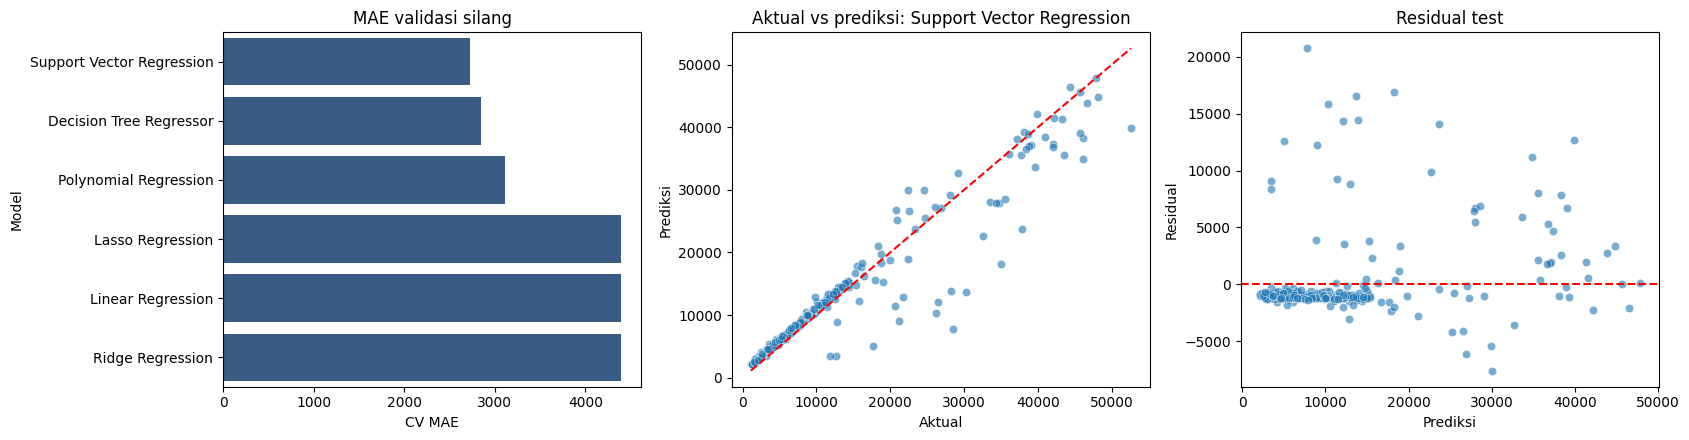

MAE menurut smoker:
        count     mean   median
smoker                         
no        213  1682.13  1112.15
yes        55  3830.00  2560.82
Ambang kuartil atas charges dari train: 17178.68
MAE test di atas ambang: 5576.42
Bias test di atas ambang (prediksi - aktual): -4052.65


In [64]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.barplot(data=evaluation, y="Model", x="CV MAE", ax=axes[0], color="#2b5c8f")
axes[0].set_title("MAE validasi silang")
sns.scatterplot(x=y_test, y=results[best_name]["pred_test"], ax=axes[1], alpha=0.6)
lo, hi = y_test.min(), y_test.max()
axes[1].plot([lo, hi], [lo, hi], "r--")
axes[1].set(xlabel="Aktual", ylabel="Prediksi", title=f"Aktual vs prediksi: {best_name}")
residual = y_test.to_numpy() - results[best_name]["pred_test"]
sns.scatterplot(x=results[best_name]["pred_test"], y=residual, ax=axes[2], alpha=0.6)
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set(xlabel="Prediksi", ylabel="Residual", title="Residual test")
plt.tight_layout()
plt.show()

diagnostic = X_test[["smoker"]].copy()
diagnostic["aktual"] = y_test
diagnostic["prediksi"] = results[best_name]["pred_test"]
diagnostic["abs_error"] = (diagnostic["aktual"] - diagnostic["prediksi"]).abs()
print("MAE menurut smoker:")
print(diagnostic.groupby("smoker")["abs_error"].agg(["count", "mean", "median"]).round(2))
high_threshold = y_train.quantile(0.75)
print("Ambang kuartil atas charges dari train:", round(high_threshold, 2))
mask_high = diagnostic["aktual"] > high_threshold
print("MAE test di atas ambang:", round(diagnostic.loc[mask_high, "abs_error"].mean(), 2))
print("Bias test di atas ambang (prediksi - aktual):",
      round((diagnostic.loc[mask_high, "prediksi"] - diagnostic.loc[mask_high, "aktual"]).mean(), 2))


# 5. Analisis

**Kondisi data.** Dari 1.338 baris, satu duplikat dibuang sehingga 1.337 baris dipakai. Tidak ada nilai kosong. Target miring ke kanan (skewness 1,515). Median biaya bukan perokok 7.345,73, sedangkan perokok 34.456,35. Korelasi BMI–biaya lebih kuat pada perokok. Korelasi ini tidak membuktikan sebab akibat.

**Perbandingan model.** Baseline Linear Regression memiliki CV MAE 4.392,59. Ridge (alpha 0,1) dan Lasso (alpha 10) hampir sama, sebab keduanya masih linier dalam fitur asal. Polynomial degree 2 menurunkan CV MAE menjadi 3.111,50; degree 3 justru 3.276,40, indikasi kapasitas tambahan tidak membantu validasi. Tree dengan max_depth 5 dan min_samples_leaf 15 mencapai CV MAE 2.851,83. SVR RBF dengan C=1 dan epsilon=0,1 paling baik menurut aturan pemilihan: CV MAE 2.723,34. Epsilon 0,3 memberi error validasi jauh lebih besar.

**Evaluasi test.** SVR mencapai MAE 2.122,92, RMSE 3.780,68, dan R² 0,901. Tree mendekati dengan MAE 2.181,94; bahkan RMSE 3.504,06 dan R² 0,915 lebih baik pada split test ini. Karena kriteria diputuskan lebih dahulu sebagai CV MAE, rekomendasi tetap SVR. Tree patut dipertimbangkan bila kesalahan besar lebih mahal. MAE train SVR 2.498,93 vs CV 2.723,34 menunjukkan sedikit kenaikan error pada validasi. Kesalahan test yang lebih kecil daripada CV bisa terjadi karena komposisi split; ini bukan jaminan untuk data baru. Grafik residual dan ringkasan per kelompok membantu melihat bias.

**Pemeriksaan kelompok.** Pada test, MAE SVR untuk bukan perokok 1.682,13 (213 baris), sedangkan untuk perokok 3.830,00 (55 baris). Pada biaya di atas kuartil ketiga train (17.178,68), MAE mencapai 5.576,42 dan rata-rata prediksi lebih rendah 4.052,65 daripada nilai aktual. Jadi metrik keseluruhan menyembunyikan kesulitan pada kelompok biaya tinggi.


# 6. Kesimpulan dan Saran

**SVR RBF** adalah pilihan awal berdasarkan CV MAE terendah (2.723,34); pada test MAE-nya 2.122,92 dan R² 0,901. **Decision Tree** layak menjadi alternatif karena RMSE test-nya lebih kecil (3.504,06 vs 3.780,68). Satu duplikat dibuang sebelum split; preprocessing dan tuning hanya memakai train melalui pipeline dan validasi silang. Hasil ini bersifat prediktif, bukan kausal.

Eksperimen lanjutan: tambah interaksi smoker × BMI secara eksplisit untuk model yang tetap mudah ditafsirkan; coba ensemble pohon; analisis residual menurut kelompok perokok dan kuantil biaya; ulangi evaluasi pada beberapa split untuk menilai ketidakpastian.
